PyTorch Domain Libraries :

- TorchText
- TorchVision
- TorchAudio

Load dataset with own custom data.


In [1]:
import torch
from torch import nn


In [2]:
torch.__version__

'2.11.0+cpu'

In [3]:
# Setup device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

Get the data from the Food 101 dataset : 101 food categories and 101000 images

Start small and increase scale when necessary: 3 food types and 10% of the images (750 training and 250 testing)



In [4]:
import requests
import zipfile
from pathlib import Path

data_path = Path("data/")
image_path = data_path/"pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} directory already exists ... skipping download")
else:
    print(f"{image_path} does not exist, creating one ...")
    image_path.mkdir(parents=True, exist_ok=True)      # ← the missing line

# Download
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print("Downloading pizza, steak, sushi data ...")
    f.write(request.content)

# Unzip
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
    print("Unzipping pizza, steak, sushi data ...")
    zip_ref.extractall(image_path)

data/pizza_steak_sushi directory already exists ... skipping download
Unzipping pizza, steak, sushi data ...


In [5]:
image_path

PosixPath('data/pizza_steak_sushi')

**2. Understanding the data**

In [6]:
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} in images {dirpath}")

In [7]:
walk_through_dir(image_path)

There are 2 directories and 0 in images data/pizza_steak_sushi
There are 3 directories and 0 in images data/pizza_steak_sushi/test
There are 0 directories and 19 in images data/pizza_steak_sushi/test/steak
There are 0 directories and 31 in images data/pizza_steak_sushi/test/sushi
There are 0 directories and 25 in images data/pizza_steak_sushi/test/pizza
There are 3 directories and 0 in images data/pizza_steak_sushi/train
There are 0 directories and 75 in images data/pizza_steak_sushi/train/steak
There are 0 directories and 72 in images data/pizza_steak_sushi/train/sushi
There are 0 directories and 78 in images data/pizza_steak_sushi/train/pizza


In [8]:
train_dir = image_path/"train"
test_dir = image_path/"test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

**2.1 Visualize an image**
- get all of the image paths
- pick a random image path using Python's 'random.choice()'
- get the image class name using 'pathlib.Path.parent.stem'
- open the image with Python
- show the image and print metadata

pizza
Random image path data/pizza_steak_sushi/train/pizza/3196721.jpg
Image class pizza
Image class 384
Image class 512


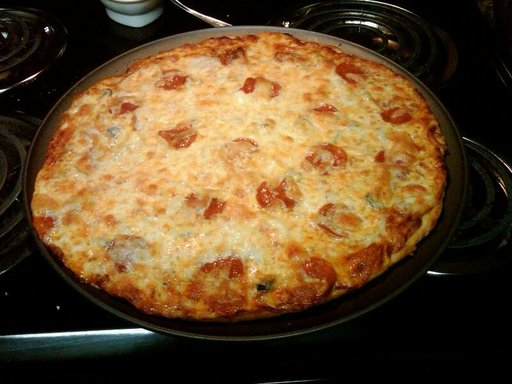

In [9]:
import random
from PIL import Image
# random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg"))
image_path_list

random_image_path = random.choice(image_path_list)
random_image_path

image_class = random_image_path.parent.stem
print(image_class)

img = Image.open(random_image_path)
print(f"Random image path {random_image_path}")
print(f"Image class {image_class}")
print(f"Image class {img.height}")
print(f"Image class {img.width}")
img

**Visualize with matplotlib**

(384, 512, 3)


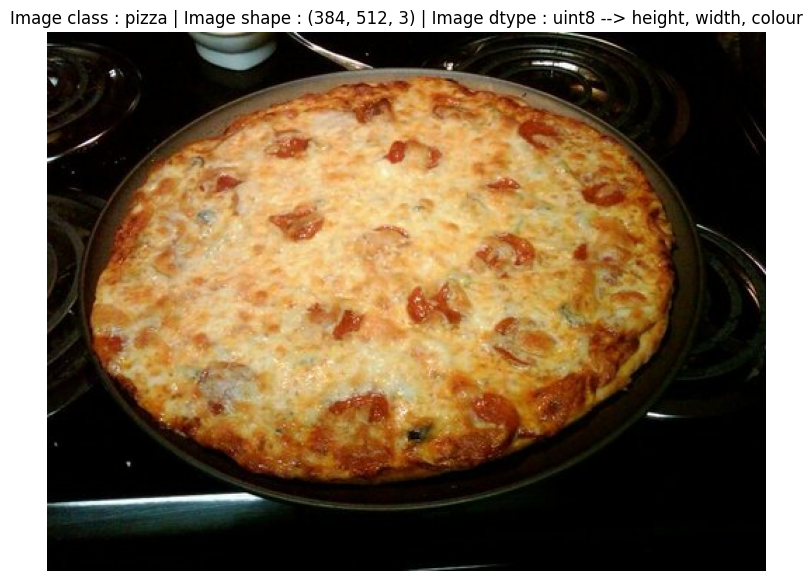

In [10]:
import numpy as np
import matplotlib.pyplot as plt

img_as_array = np.asarray(img)
print(img_as_array.shape)

plt.figure(figsize=(10,7))
plt.imshow(img_as_array)
plt.title(f"Image class : {image_class} | Image shape : {img_as_array.shape} | Image dtype : {img_as_array.dtype} --> height, width, colour")
plt.axis(False);

In [11]:
# image in numerical format
print(img_as_array)

[[[3 3 3]
  [3 3 3]
  [3 3 3]
  ...
  [8 7 2]
  [5 6 1]
  [6 8 3]]

 [[1 1 1]
  [1 1 1]
  [1 1 1]
  ...
  [6 5 0]
  [3 4 0]
  [2 4 0]]

 [[0 2 1]
  [0 2 1]
  [1 1 1]
  ...
  [6 5 0]
  [4 5 0]
  [0 2 0]]

 ...

 [[1 1 1]
  [1 1 1]
  [1 1 1]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[1 1 1]
  [1 1 1]
  [1 1 1]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[1 1 1]
  [1 1 1]
  [1 1 1]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


**3. Transforming our image data with PyTorch:**

- turn your target data into tensors
- turn it into a 'torch.utils.data.Dataset' and subsequently a 'torch.utils.data'


In [12]:
import torch
from torch. utils.data import DataLoader
from torchvision import datasets, transforms

In [13]:
# Write a transform for image 'transform an image' using Compose
data_transform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

In [14]:
data_transform(img)

tensor([[[0.0392, 0.0353, 0.0824,  ..., 0.0078, 0.0078, 0.0118],
         [0.0392, 0.0275, 0.0549,  ..., 0.0706, 0.0745, 0.1020],
         [0.0353, 0.0235, 0.0510,  ..., 0.1529, 0.1176, 0.1020],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0039, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0039, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.0275, 0.0157, 0.0549,  ..., 0.0078, 0.0039, 0.0078],
         [0.0157, 0.0118, 0.0392,  ..., 0.0667, 0.0745, 0.1020],
         [0.0078, 0.0118, 0.0353,  ..., 0.1451, 0.1098, 0.0902],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0039, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.0078, 0.0078, 0.0235,  ..., 0.0039, 0.0078, 0.0078],
         [0.0039, 0.0078, 0.0196,  ..., 0.0431, 0.0549, 0.0902],
         [0.0039, 0.0078, 0.0196,  ..., 0.0941, 0.0745, 0.

In [15]:
data_transform(img).shape

torch.Size([3, 64, 64])

In [16]:
data_transform(img).dtype

torch.float32

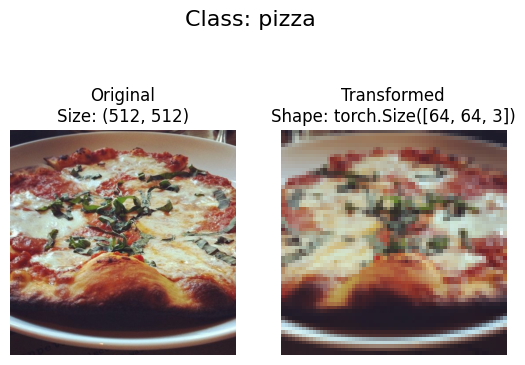

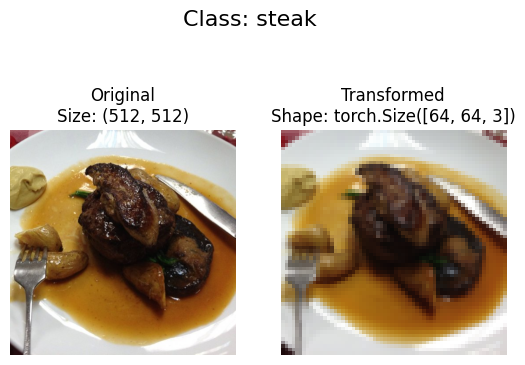

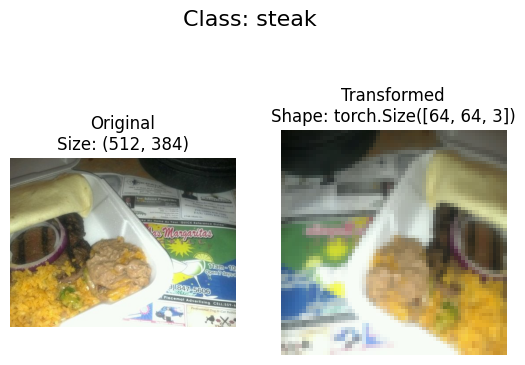

In [17]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):
    random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis("off")

            transformed_image = transform(f).permute(1, 2, 0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_paths=image_path_list,
                        transform=data_transform,
                        n=3,
                        seed=42)

**4. Option 1 : Loading image data** using 'ImageFolder'

In [18]:
# Use image folder to create a dataset
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir,
                                  transform=data_transform,
                                  target_transform=None)
test_data = datasets.ImageFolder(root=test_dir,
                                  transform=data_transform,
                                  target_transform=None)
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [19]:
train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [20]:
# Get class names as a list
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [21]:
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [22]:
len(train_data), len(test_data)

(225, 75)

In [23]:
train_data.samples[0]


('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [24]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor: \n{img}")
print(f"Image shape: {img.shape}")
print(f"Image label: {label}")
print(f"Label class: {class_names[label]}")

Image tensor: 
tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0

Original shape: torch.Size([3, 64, 64]) C,H,W
Permuted shape: torch.Size([64, 64, 3]) H,W,C


Text(0.5, 1.0, 'Image class : pizza')

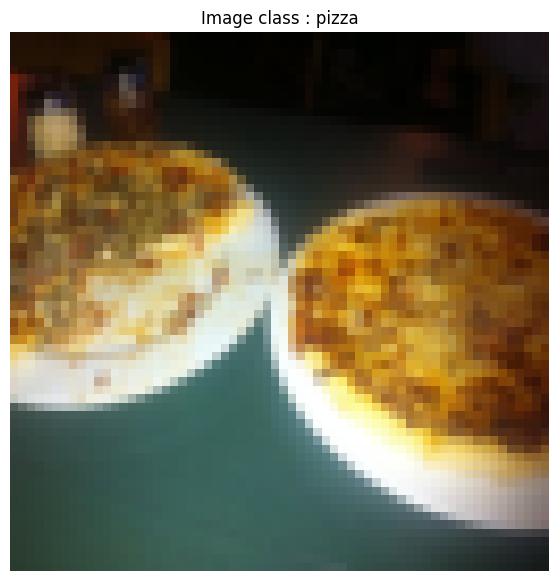

In [25]:
# Rearrange the order dimensions
img_permute = img.permute(1,2,0)

print(f"Original shape: {img.shape} C,H,W")
print(f"Permuted shape: {img_permute.shape} H,W,C")

plt.figure(figsize=(10,7))
plt.imshow(img_permute)
plt.axis("off")
plt.title(f"Image class : {class_names[label]}")

**4.1 Turn loaded images into 'DataLoader'**

Turn our 'Dataset' into iterables and we can customize

In [26]:
import os
os.cpu_count()

2

In [27]:
from torch.utils.data import DataLoader
BATCH_SIZE=1
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              num_workers=1,    # how many CPU
                              shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                              batch_size=BATCH_SIZE,
                              num_workers=1,    # how many CPU
                              shuffle=False)
train_dataloader, test_dataloader


(<torch.utils.data.dataloader.DataLoader at 0x7f31e0d796a0>,
 <torch.utils.data.dataloader.DataLoader at 0x7f31b95d7d90>)

In [28]:
len(train_dataloader), len(test_dataloader)

(225, 75)

In [29]:
img, label = next(iter(train_dataloader))

print(f"Image shape: {img.shape}")
print(f"Image label: {label.shape}")

BATCH_SIZE

Image shape: torch.Size([1, 3, 64, 64])
Image label: torch.Size([1])


1

**4.1 Option 2 : and without 'DataLoader' ?**

- Want to be able to load images from file
- Want to be able to get class names from the Dataset
- Want to be able to get classes as dictionary from the Dataset


In [30]:
import os
import pathlib
import torch

from PIL import Image
from typing import Tuple, Dict, List
from torchvision import transforms
from typing import Tuple, Dict, List


In [31]:
train_data.classes, train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

5.1 Creating a helper function to get class names

1. Get the class names using 'os.scandir()' to traverse a target directory
2. Raise an error if the class nales aren t found
3. Turn the class names into a dict and a list and return them


In [32]:
target_directory = train_dir
print(f"Target dir: {target_directory}")

class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [33]:
list(os.scandir(target_directory))

[<DirEntry 'steak'>, <DirEntry 'sushi'>, <DirEntry 'pizza'>]

In [34]:
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
  classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
  if not classes:
    raise FileNotFoundError(f"Couldn't find any classes in {directory}.")
  class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
  return classes, class_to_idx

In [35]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

**5.2 Create a custom dataset to replicate 'ImageFolder'**

1. Subclass 'torch.utils.data.Dataset'
2. Init our subclass with a target directory
3. Create several attributes
- paths - paths of our images
- tranform - the transform we'd like to use
- classes - a list of the target classes
- classes_to_idw - a dict of the target classes mapped to integer labels
4. Create a function to 'load_images()', this function will open an image
5. Overwrite the __len()__ method to return the lenght of our dataset
6. Overwrite the __getitem()__ method to return a given sample when passed an index

In [36]:
import pathlib                                    # work with filesystem paths as Path objects
from typing import Tuple                          # needed for the Tuple[...] return annotation below
from PIL import Image                             # needed for Image.open and the Image.Image annotation
import torch
from torch.utils.data import Dataset              # base class PyTorch expects for any dataset

# replicates DataFolder class but custom made
class ImageFolderCustom(Dataset):                 # inherit from Dataset → DataLoader knows how to use this
    def __init__(self,
                 targ_dir: str,                   # root folder, e.g. "data/pizza_steak_sushi/train"
                 transform=None):                 # optional transform (resize, ToTensor…); None = raw images

        # glob("*/*.jpg") = every .jpg exactly one level deep:
        #   targ_dir/pizza/image_01.jpg, targ_dir/steak/image_02.jpg, etc.
        # the first * captures the class folder, the second the filename.
        # list(...) because glob returns a generator, which can only be walked once.
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))

        self.transform = transform                # stored so __getitem__ can apply it later

        # find_classes (defined in an earlier cell) returns two things:
        #   - the sorted list of class names   → ['pizza', 'steak', 'sushi']
        #   - the name → index dict            → {'pizza': 0, 'steak': 1, 'sushi': 2}
        self.classes, self.class_to_idx = find_classes(targ_dir)

    # helper method (not required by Dataset): open one image by its position in self.paths.
    # -> Image.Image is a type annotation: documents the return type, enforces nothing at runtime.
    def load_image(self, index: int) -> Image.Image:
        image_path = self.paths[index]            # self.paths[3] → PosixPath('data/.../steak/42.jpg')
        return Image.open(image_path)             # a PIL object, not a tensor yet

    # required by Dataset #1: how many samples are there?
    # DataLoader calls this to know how many batches to produce.
    def __len__(self):
        return len(self.paths)

    # required by Dataset #2: return sample number `index` as an (image, label) pair.
    # this is what runs every time the DataLoader pulls an item.
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        img = self.load_image(index)
        class_name = self.paths[index].parent.name
        class_idx = self.class_to_idx[class_name]

        if self.transform:
            return self.transform(img), class_idx
        else:
            return img, class_idx

In [37]:
from torchvision import transforms
train_transforms = transforms.Compose([
                                      transforms.Resize((64,64)),
                                      transforms.RandomHorizontalFlip(p=0.5),
                                      transforms.ToTensor()
])

test_transforms = transforms.Compose([
                                      transforms.Resize((64,64)),
                                      # skip manipulating RH
                                       transforms.ToTensor()
])



In [38]:
train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=train_transforms)

test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=test_transforms)
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7f31e0d7af90>,
 <__main__.ImageFolderCustom at 0x7f31b9605a90>)

In [39]:
# the original one
train_data

Dataset ImageFolder
    Number of datapoints: 225
    Root location: data/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )

In [40]:
len(train_data), len(train_data_custom)

(225, 225)

In [41]:
len(test_data), len(test_data_custom)

(75, 75)

In [42]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [43]:
# check for equality between original ImageFolder and ImageFolderCustomDataset
print(train_data.class_to_idx == train_data_custom.class_to_idx)
print(test_data.class_to_idx == test_data_custom.class_to_idx)

True
True


**5.3 Create a fnction to display random images**
1. Take in a 'Dataset' and a number of other parameters such as class nales and how many images to visualize.
2. To prevent the display getting out of hand, let's cap the nuumber of images to see at 10
3. Set the random seed
4. Get a list of random sample indexes from a target sample
5. Setup a matplotlib plot
6. Loop through the random sample images and plot them with matplotlib
7. Make sure the dimensions of our images line up with matplotlib (HWC)

In [44]:
# 1. Create a function to take in a dataset
def display_random_images(dataset: torch.utils.data.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):

    # 2. Adjust display if n is too high
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")

    # 3. Set the seed
    if seed:
        random.seed(seed)

    # 4. Get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # 5. Setup plot — width scales with n so titles don't collide
    plt.figure(figsize=(3 * n, 5))

    # 6. Loop through random indexes and plot them with matplotlib
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust tensor dimensions for plotting
        targ_image_adjust = targ_image.permute(1, 2, 0)  # [C, H, W] -> [H, W, C]

        # Plot adjusted samples
        plt.subplot(1, n, i + 1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")

        title = ""
        if classes:
            title = f"Class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title, fontsize=9)

    plt.tight_layout()

In [45]:
random.sample(range(len(train_data_custom)), k=10)

[62, 57, 35, 188, 26, 173, 189, 139, 22, 151]

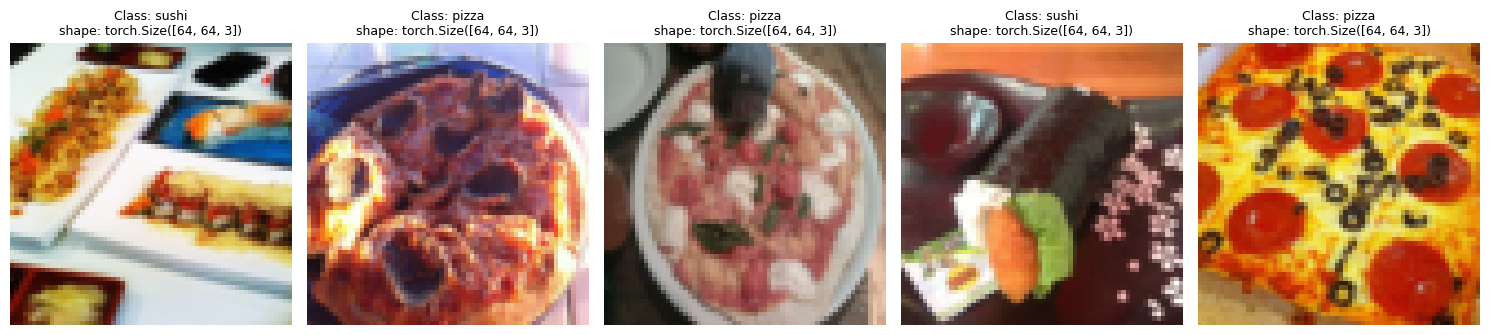

In [46]:
# Display random images from the ImageFolder
display_random_images(train_data,
                      n=5,
                      classes=class_names,
                      seed=42)


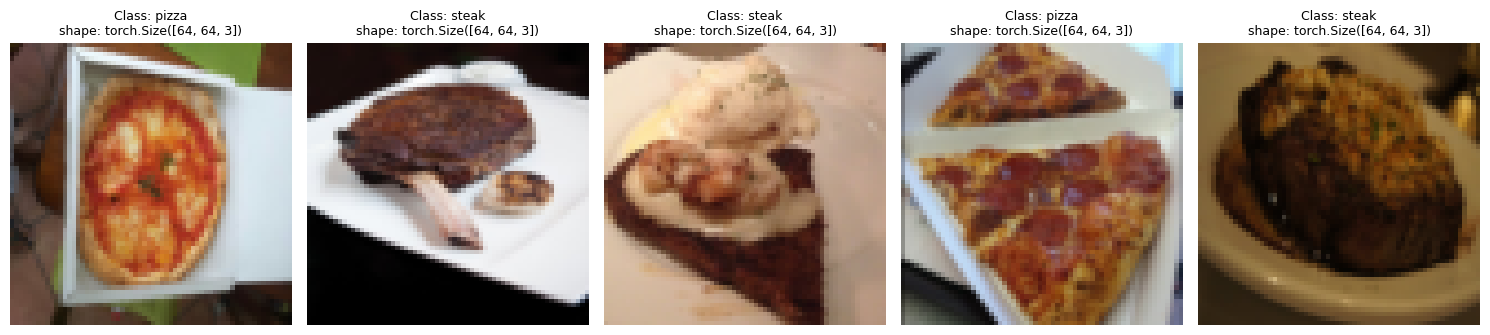

In [47]:
# Display random images from the ImageFolderCustomDataset
display_random_images(train_data_custom,
                      n=5,
                      classes=class_names,
                      seed=42)

**5.4 Turn dataset into a dataloader**

In [48]:
from torch.utils.data import DataLoader
BATCH_SIZE=32

train_dataloader_custom = DataLoader(dataset=train_data_custom,
                                  batch_size=BATCH_SIZE,
                                  num_workers=0,
                                  shuffle=True)

test_dataloader_custom = DataLoader(dataset=test_data_custom,
                                    batch_size=BATCH_SIZE,
                                    num_workers=0,
                                    shuffle=False)

train_dataloader_custom, test_dataloader_custom




(<torch.utils.data.dataloader.DataLoader at 0x7f31b9497ed0>,
 <torch.utils.data.dataloader.DataLoader at 0x7f31e0de6ea0>)

In [49]:
# Get image and label from custom dataloader
img_custom, label_custom = next(iter(train_dataloader_custom))
img_custom.shape, label_custom.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

**6. Other forms of transforms**

adding more data by creating copies by artificially adding diversity to your data by aplying image transformations to existing images
- sheering
- rotating
- croping ...

Generalize model to unseen data (+/- 5% performance boost)
- trivial augment

In [50]:
from torchvision import transforms

# trivial augment
train_transform = transforms.Compose([
                                      transforms.Resize(size=(224,224)),
                                      transforms.TrivialAugmentWide(num_magnitude_bins=31),
                                      transforms.ToTensor()
])

test_transform = transforms.Compose([
                                      transforms.Resize(size=(224,224)),
                                      transforms.ToTensor()
])

In [51]:
# Get all the image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))
image_path_list[:10]

[PosixPath('data/pizza_steak_sushi/test/steak/894825.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/27415.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1882831.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/100274.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/3873283.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/673127.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/690177.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1868005.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/296375.jpg'),
 PosixPath('data/pizza_steak_sushi/test/steak/1627703.jpg')]

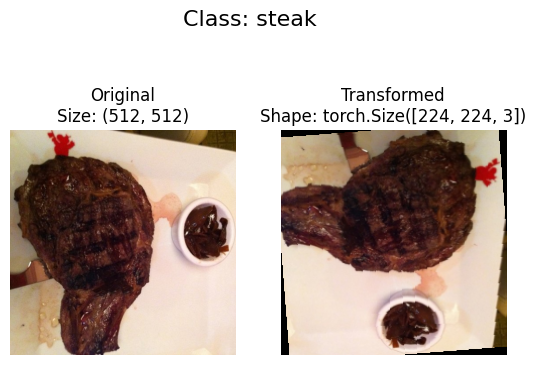

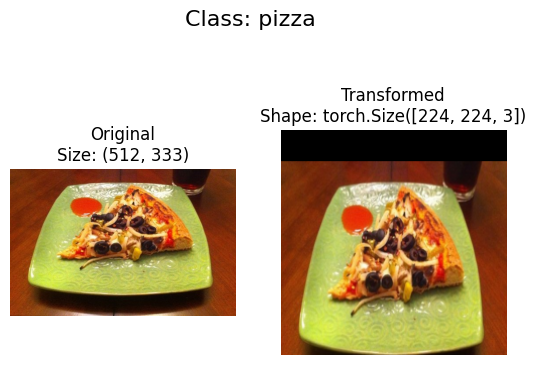

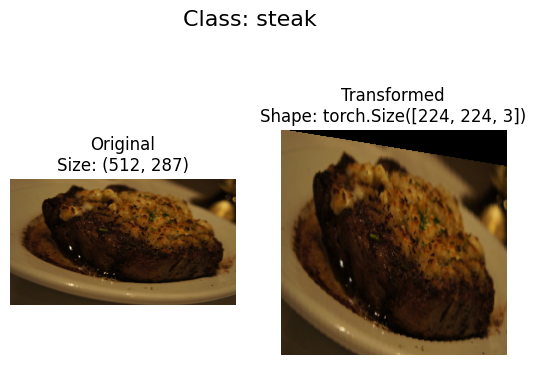

In [52]:
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transform,
    n=3,
    seed=None
)

**7. Model 0 : TinyVGG architecture from the CNN website**

7.1 Creating transforms and loading data to Model 0

In [53]:
# Create a simple transform
simple_transform = transforms.Compose([
                                      transforms.Resize(size=(64,64)),
                                      transforms.ToTensor()
])

In [54]:
from torchvision import datasets

train_data_simple = datasets.ImageFolder(root=train_dir,
                                        transform=simple_transform)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=simple_transform)

# Turn the datasets into DataLoaders
import os
from torch.utils.data import DataLoader
BATCH_SIZE=32

# Create DataLoader
train_dataloader_simple = DataLoader(dataset=train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     num_workers=0,
                                     shuffle=True)

test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=0,
                                    shuffle=False)

train_dataloader_simple, test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x7f31e0de7a80>,
 <torch.utils.data.dataloader.DataLoader at 0x7f31b9571d90>)

7.2 Build Tiny VGG architecture from CNN

In [55]:
class TinyVGG(nn.Module):
    def __init__(self,
                 input_shape: int,
                 hidden_units: int,
                 output_shape: int) -> None:
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=0),
            nn.ReLU(),

            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=0),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2,
                         stride=2)    # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=0),
            nn.ReLU(),

            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)    # default stride value is same as kernel_size
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*13*13,
                      out_features=output_shape)
        )

    def forward(self, x):
      x = self.conv_block_1(x)
      # print(x.shape)
      x = self.conv_block_2(x)
      # print(x.shape)
      x = self.classifier(x)
      # print(x.shape)
      return x

In [56]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(class_names)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

7.4 Dummy forward pass

In [57]:
# Get a single image batch
image_batch, label_batch = next(iter(train_dataloader_simple))
image_batch.shape, label_batch.shape


(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [58]:
model_0(image_batch).to(device)
# this is random weights

tensor([[ 2.0795e-02, -1.9510e-03,  9.5212e-03],
        [ 1.8440e-02,  2.4668e-03,  6.6609e-03],
        [ 1.7695e-02,  1.0282e-03,  9.4975e-03],
        [ 2.4446e-02, -3.3489e-03,  9.5877e-03],
        [ 1.9939e-02,  6.9131e-04,  1.0778e-02],
        [ 2.1281e-02,  2.0434e-03,  5.0046e-03],
        [ 2.0996e-02,  1.6415e-04,  1.2481e-02],
        [ 2.1566e-02, -1.9607e-03,  9.7175e-03],
        [ 2.4500e-02, -4.7904e-03,  8.5394e-03],
        [ 2.0239e-02, -4.7979e-04,  1.0907e-02],
        [ 2.2219e-02, -4.1816e-04,  9.8173e-03],
        [ 2.2318e-02, -2.1642e-03,  9.4428e-03],
        [ 2.1851e-02, -3.7225e-03,  8.3784e-03],
        [ 2.2881e-02, -1.7559e-03,  1.0299e-02],
        [ 2.1635e-02, -4.3995e-03,  9.4990e-03],
        [ 2.2101e-02, -4.1469e-03,  9.3904e-03],
        [ 2.1226e-02, -4.4215e-03,  1.1476e-02],
        [ 2.1698e-02, -2.7458e-03,  8.4966e-03],
        [ 1.9974e-02, -3.1665e-07,  8.4496e-03],
        [ 1.8308e-02,  1.6378e-03,  8.5491e-03],
        [ 2.0768e-02

**7.4 Use 'torchinfo' to get a summary**

In [59]:
# really cool !!

try:
  import torchinfo
except:
  !pip install torchinfo
  import torchinfo

from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 30, 30]           --
│    └─Conv2d: 2-1                       [1, 10, 62, 62]           280
│    └─ReLU: 2-2                         [1, 10, 62, 62]           --
│    └─Conv2d: 2-3                       [1, 10, 60, 60]           910
│    └─ReLU: 2-4                         [1, 10, 60, 60]           --
│    └─MaxPool2d: 2-5                    [1, 10, 30, 30]           --
├─Sequential: 1-2                        [1, 10, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 10, 28, 28]           910
│    └─ReLU: 2-7                         [1, 10, 28, 28]           --
│    └─Conv2d: 2-8                       [1, 10, 26, 26]           910
│    └─ReLU: 2-9                         [1, 10, 26, 26]           --
│    └─MaxPool2d: 2-10                   [1, 10, 13, 13]           --
├─Sequentia

**7.5. Training and testing on the custom dataset**

- train_step() - takes in a model and dataloader and trains the model on the dataloader
- test_test() - takes in a model and dataloader and evaluates the model on the dataloader

In [60]:
def train_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer,
              device: torch.device):
  # Put the model in train mode
  model.train()

  # Setup train loss and train accuracy values
  train_loss, train_acc = 0,0

  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    # Send data to the target device
    X, y = X.to(device), y.to(device)

    # Forward pass
    y_pred = model(X)

    # Calculate the loss
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    # Optimizer zero grad
    optimizer.zero_grad()

    # Loss backward
    loss.backward()

    # Optimizer
    optimizer.step()

    # Calculate accuracy metric
    y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_pred)


  # Adjust metrics to get average loss and accuracy per batch
  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  return train_loss, train_acc

In [61]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device):
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference mode
    with torch.inference_mode():
        for batch, (X, y) in enumerate(dataloader):
            # Send data to the target device
            X, y = X.to(device), y.to(device)

            # Forward pass
            test_pred_logits = model(X)

            # Calculate the loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item() / len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

**7.6 Creating a 'train()' function to combine 'train_step()' and 'test_step()'**

In [62]:
from tqdm.auto import tqdm

def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module,
          epochs: int,
          device: torch.device):

    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}

    # Loop through training and testing
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           device=device)
        test_loss, test_acc = test_step(model=model,
                                        dataloader=test_dataloader,
                                        loss_fn=loss_fn,
                                        device=device)

        print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")

        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    return results

**7.7 Train and evaluate Model_0**

In [63]:
torch.manual_seed(42)

NUM_EPOCHS = 50

model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(),
                             lr=0.001)

from timeit import default_timer as timer
start_time = timer()

model_0_results = train(model=model_0,
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS,
                        device=device)

end_time = timer()
print(f"Total training time: {end_time - start_time:.3f} seconds")

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch: 0 | Train loss: 1.1063 | Train acc: 0.3047 | Test loss: 1.0983 | Test acc: 0.3011
Epoch: 1 | Train loss: 1.0998 | Train acc: 0.3281 | Test loss: 1.0697 | Test acc: 0.5417
Epoch: 2 | Train loss: 1.0869 | Train acc: 0.4883 | Test loss: 1.0808 | Test acc: 0.4924
Epoch: 3 | Train loss: 1.0842 | Train acc: 0.3984 | Test loss: 1.0608 | Test acc: 0.5833
Epoch: 4 | Train loss: 1.0662 | Train acc: 0.4141 | Test loss: 1.0654 | Test acc: 0.5644
Epoch: 5 | Train loss: 1.0305 | Train acc: 0.4336 | Test loss: 1.0139 | Test acc: 0.5426
Epoch: 6 | Train loss: 0.9854 | Train acc: 0.4219 | Test loss: 0.9323 | Test acc: 0.5938
Epoch: 7 | Train loss: 0.9663 | Train acc: 0.5781 | Test loss: 0.9986 | Test acc: 0.4432
Epoch: 8 | Train loss: 0.9238 | Train acc: 0.5977 | Test loss: 1.0669 | Test acc: 0.3324
Epoch: 9 | Train loss: 0.9969 | Train acc: 0.4648 | Test loss: 1.0632 | Test acc: 0.4044
Epoch: 10 | Train loss: 0.8697 | Train acc: 0.5195 | Test loss: 0.9761 | Test acc: 0.4830
Epoch: 11 | Train lo

In [64]:
model_0_results

{'train_loss': [1.106319084763527,
  1.0998057276010513,
  1.0868544578552246,
  1.0842333287000656,
  1.0662163645029068,
  1.0305046811699867,
  0.9854388535022736,
  0.9663243293762207,
  0.9237585514783859,
  0.9968554675579071,
  0.8697074726223946,
  0.9242511913180351,
  0.7838825695216656,
  0.9043351262807846,
  0.7889668345451355,
  0.7488975711166859,
  0.7730635069310665,
  0.7477861270308495,
  0.7746242582798004,
  0.7755993604660034,
  0.7839249894022942,
  0.7888880670070648,
  0.7334330417215824,
  0.8690939769148827,
  0.6534039881080389,
  0.7042508721351624,
  0.6319012260064483,
  0.6576803475618362,
  0.6021412936970592,
  0.7660123705863953,
  0.6635136008262634,
  0.5776484631933272,
  0.5765591794624925,
  0.5751331299543381,
  0.5561276823282242,
  0.5706560704857111,
  0.595952570438385,
  0.6601458340883255,
  0.6936991177499294,
  0.5918710604310036,
  0.6997936405241489,
  0.6911058165132999,
  0.6435640044510365,
  0.6514636911451817,
  0.7149924598634243

**7.8 Plot the loss curve of Model_0**

https://developers.google.com/machine-learning/crash-course/overfitting/interpreting-loss-curves$0

**Reduce overfitting:**
- get more data
- better quality data
- augment data
- simplify the model
- use learning rate decay (slowly decrease the lr as the loss decreases)
- early stopping

**Reduce underfitting:**
- add layers
- tweak lr
- more epochs
- use transfer learning
- don't touch your model too much (preventing too much overfitting)

In [65]:
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [66]:
def plot_loss_curves(results: Dict[str, List[float]]):
    loss = results["train_loss"]
    test_loss = results["test_loss"]

    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="train_loss")
    plt.plot(epochs, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)          # ← 2, not 3
    plt.plot(epochs, accuracy, label="train_accuracy")
    plt.plot(epochs, test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

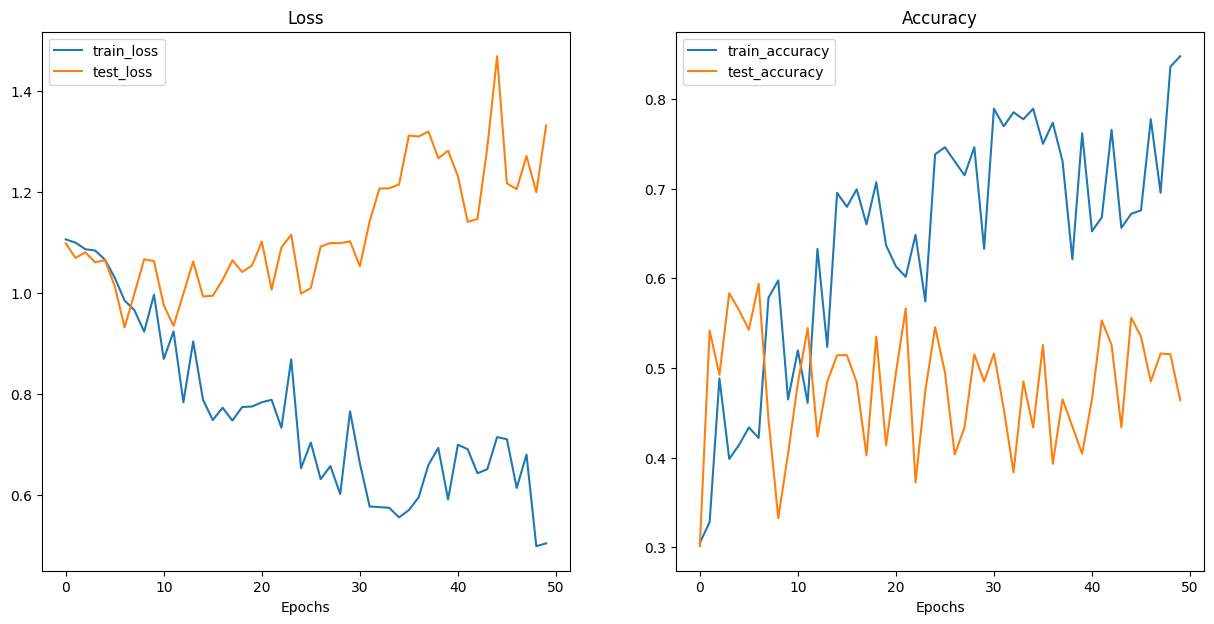

In [67]:
plot_loss_curves(model_0_results)

**9. Data augmentation** : manipulate images to increase diversity

In [68]:
# Create a training transform with TrivialAugment

from torchvision import transforms
train_transform_trivial = transforms.Compose([
                                              transforms.Resize(size=(64,64)),
                                              transforms.TrivialAugmentWide(num_magnitude_bins=31),
                                              transforms.ToTensor()
])

test_transform_simple = transforms.Compose([
                                           transforms.Resize(size=(64,64)),
                                           transforms.ToTensor()
])


In [69]:
# Create train and test Dataset's and DataLoader with data augmentation

from torchvision import datasets
train_data_augmented = datasets.ImageFolder(root=train_dir,
                                           transform=train_transform_trivial)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                           transform=test_transform_simple)



In [70]:
# Turn datasets to dataloaders
import os
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)
train_dataloader_augmented = DataLoader(dataset=train_data_augmented,
                                        batch_size=BATCH_SIZE,
                                        num_workers=NUM_WORKERS,
                                        shuffle=True)

test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=NUM_WORKERS,
                                    shuffle=False)

train_dataloader_augmented, test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x7f31b977f130>,
 <torch.utils.data.dataloader.DataLoader at 0x7f31b977f350>)

In [71]:
# Construct and train Model_1
# Same model architecture except this time we've augmented the training data

torch.manual_seed(42)
model_1 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data_augmented.classes)).to(device)

model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [72]:
torch.manual_seed(42)

NUM_EPOCHS = 50


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(),
                             lr=0.001)

# start timer

from timeit import default_timer as timer
start_time = timer()

model_1_results = train(model=model_1,
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS,
                        device=device)

end_time = timer()
print(f"Total training time: {end_time - start_time:.3f} seconds")


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch: 0 | Train loss: 1.1049 | Train acc: 0.2500 | Test loss: 1.1019 | Test acc: 0.2604
Epoch: 1 | Train loss: 1.0807 | Train acc: 0.4258 | Test loss: 1.1261 | Test acc: 0.2604
Epoch: 2 | Train loss: 1.0712 | Train acc: 0.4258 | Test loss: 1.1593 | Test acc: 0.2604
Epoch: 3 | Train loss: 1.1253 | Train acc: 0.3047 | Test loss: 1.1581 | Test acc: 0.2604
Epoch: 4 | Train loss: 1.0865 | Train acc: 0.4258 | Test loss: 1.1554 | Test acc: 0.3333
Epoch: 5 | Train loss: 1.0858 | Train acc: 0.3828 | Test loss: 1.1434 | Test acc: 0.2708
Epoch: 6 | Train loss: 1.0669 | Train acc: 0.4961 | Test loss: 1.1279 | Test acc: 0.3021
Epoch: 7 | Train loss: 1.0813 | Train acc: 0.3438 | Test loss: 1.1107 | Test acc: 0.2812
Epoch: 8 | Train loss: 1.0833 | Train acc: 0.4258 | Test loss: 1.1015 | Test acc: 0.3229
Epoch: 9 | Train loss: 1.0079 | Train acc: 0.5469 | Test loss: 0.9900 | Test acc: 0.4839
Epoch: 10 | Train loss: 0.9818 | Train acc: 0.4414 | Test loss: 0.9790 | Test acc: 0.3920
Epoch: 11 | Train lo

In [73]:
model_1_results

{'train_loss': [1.104914203286171,
  1.0806865319609642,
  1.0711720064282417,
  1.125308334827423,
  1.0865339040756226,
  1.085762396454811,
  1.0668861046433449,
  1.0813254415988922,
  1.083287663757801,
  1.0078872665762901,
  0.9817521646618843,
  0.9391331449151039,
  0.9750868305563927,
  1.0280800610780716,
  0.9538201689720154,
  0.9623812660574913,
  1.0558865293860435,
  0.9076091647148132,
  0.8694915696978569,
  0.9427509978413582,
  0.9181914180517197,
  1.0395839661359787,
  0.9567111134529114,
  0.9195049330592155,
  0.9396143853664398,
  1.0276240929961205,
  0.9835196062922478,
  0.9448764398694038,
  0.8992741405963898,
  0.9054276123642921,
  0.8204591311514378,
  0.962516762316227,
  0.8694741036742926,
  0.9018673747777939,
  1.0190022215247154,
  1.0098981708288193,
  0.9310575872659683,
  0.9747050777077675,
  0.9631686881184578,
  1.011748693883419,
  0.9872320592403412,
  0.9140382558107376,
  0.9358617141842842,
  0.8750782385468483,
  1.1224270462989807,
  

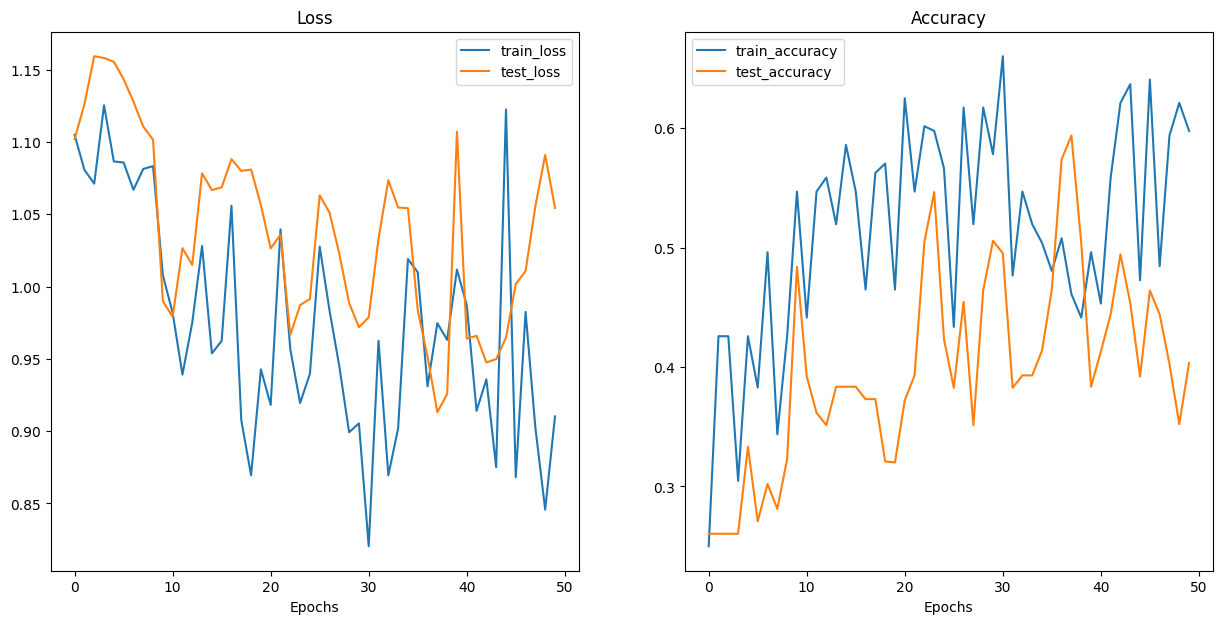

In [74]:
# plot the loss curve

plot_loss_curves(model_1_results)

**10. Compare model results**

- hard coding (what we are doing)
- 'tensorboard'
- weights and biaises : https://wandb.ai/site/$0



In [75]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df, model_1_df

(    train_loss  train_acc  test_loss  test_acc
 0     1.106319   0.304688   1.098321  0.301136
 1     1.099806   0.328125   1.069690  0.541667
 2     1.086854   0.488281   1.080757  0.492424
 3     1.084233   0.398438   1.060832  0.583333
 4     1.066216   0.414062   1.065396  0.564394
 5     1.030505   0.433594   1.013929  0.542614
 6     0.985439   0.421875   0.932304  0.593750
 7     0.966324   0.578125   0.998642  0.443182
 8     0.923759   0.597656   1.066946  0.332386
 9     0.996855   0.464844   1.063165  0.404356
 10    0.869707   0.519531   0.976106  0.482955
 11    0.924251   0.460938   0.935142  0.544508
 12    0.783883   0.632812   0.998865  0.423295
 13    0.904335   0.523438   1.062712  0.484848
 14    0.788967   0.695312   0.993377  0.514205
 15    0.748898   0.679688   0.994610  0.514205
 16    0.773064   0.699219   1.026252  0.483902
 17    0.747786   0.660156   1.064764  0.402462
 18    0.774624   0.707031   1.041773  0.535038
 19    0.775599   0.636719   1.054570  0

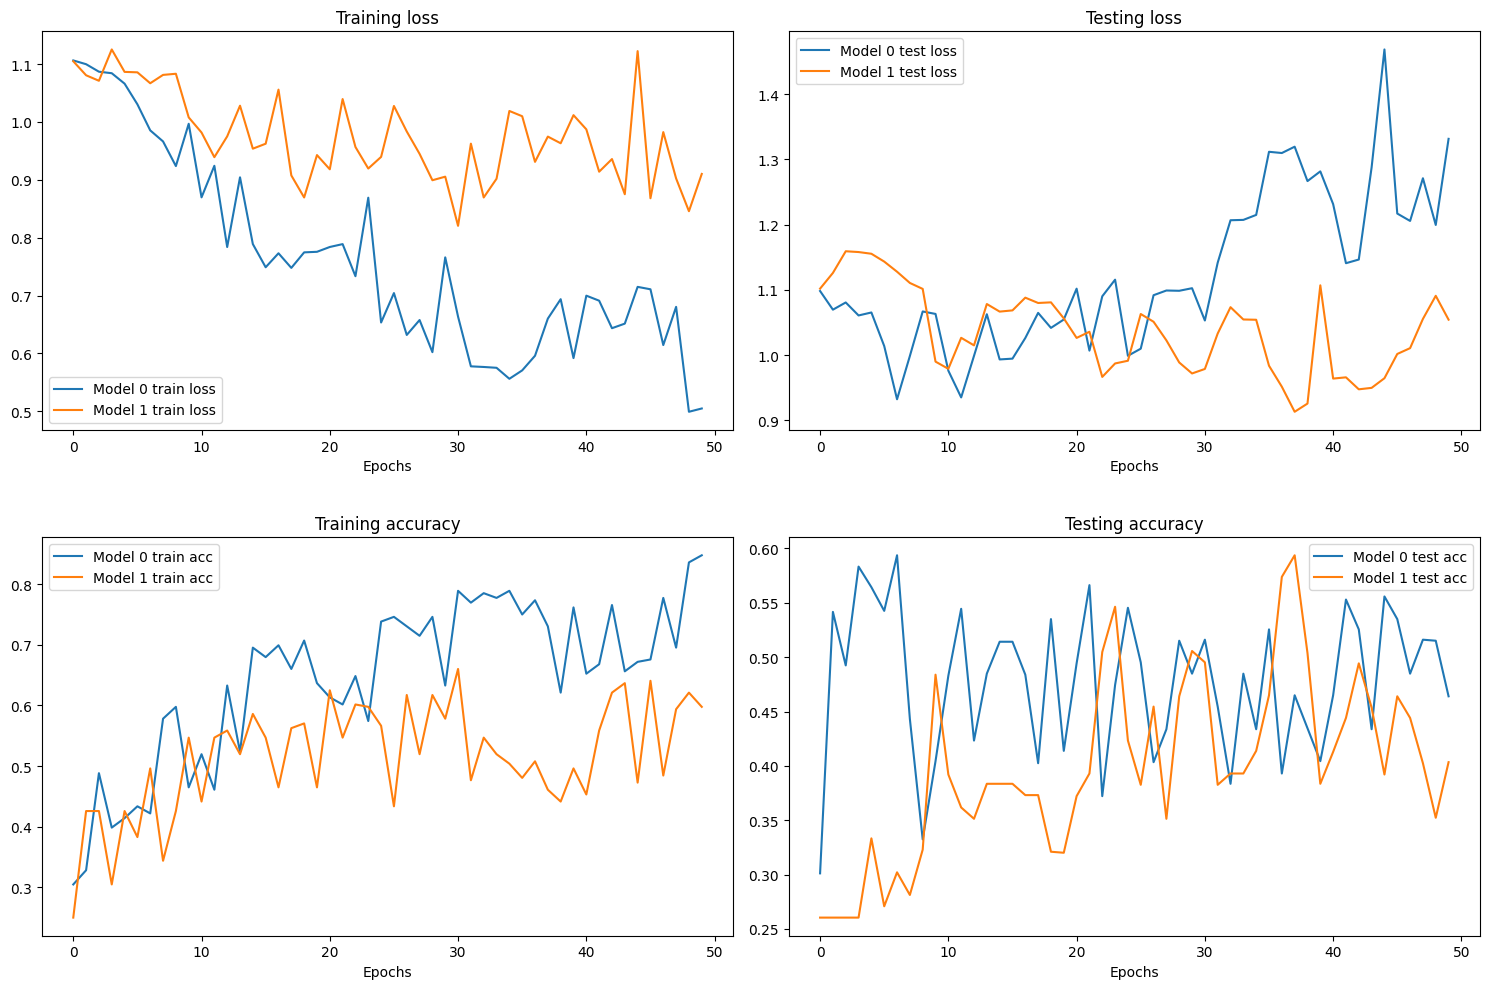

In [76]:
plt.figure(figsize=(15, 10))

epochs = range(len(model_0_df))

# Train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0 train loss")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1 train loss")
plt.title("Training loss")
plt.xlabel("Epochs")
plt.legend()

# Test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0 test loss")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1 test loss")
plt.title("Testing loss")
plt.xlabel("Epochs")
plt.legend()

# Train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0 train acc")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1 train acc")
plt.title("Training accuracy")
plt.xlabel("Epochs")
plt.legend()

# Test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0 test acc")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1 test acc")
plt.title("Testing accuracy")
plt.xlabel("Epochs")
plt.legend()

plt.tight_layout(h_pad=3)

**11. Making prediction on a custom image**

Testing the model on sample/image that's not in the database

In [77]:
import requests

custom_image_path = data_path / "04-pizza-dad.jpeg"

if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

data/04-pizza-dad.jpeg already exists, skipping download.


- in tensor form with datatype torch.float32
- of shape 64x64x3
- on the right device


In [78]:
import torchvision

custom_image_unit8 = torchvision.io.read_image(str(custom_image_path))
custom_image_unit8

tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)

In [80]:
print(f"Custom image tensor: {custom_image_unit8}")
print(f"Custom image shape: {custom_image_unit8.shape}")
print(f"Custom image dtype: {custom_image_unit8.dtype}")

Custom image tensor: tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)
Custom image shape: torch.Size([3, 4032, 3024])
Custom image dtype

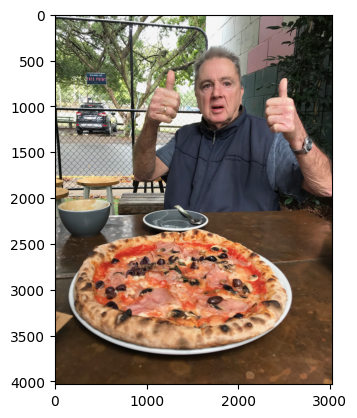

In [81]:
plt.imshow(custom_image_unit8.permute(1,2,0));

Making a prediction with a train PyTorch model


In [82]:
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32) / 255
custom_image

tensor([[[0.6039, 0.6784, 0.7098,  ..., 0.0824, 0.0706, 0.0549],
         [0.5725, 0.6471, 0.7098,  ..., 0.0824, 0.0706, 0.0588],
         [0.4863, 0.5725, 0.6745,  ..., 0.0706, 0.0667, 0.0588],
         ...,
         [0.2824, 0.2314, 0.1765,  ..., 0.5961, 0.5882, 0.5804],
         [0.2510, 0.2157, 0.1608,  ..., 0.5882, 0.5765, 0.5647],
         [0.2510, 0.2353, 0.1804,  ..., 0.5843, 0.5725, 0.5608]],

        [[0.6706, 0.7451, 0.7569,  ..., 0.0863, 0.0745, 0.0588],
         [0.6392, 0.7137, 0.7569,  ..., 0.0863, 0.0745, 0.0627],
         [0.5529, 0.6392, 0.7216,  ..., 0.0745, 0.0706, 0.0627],
         ...,
         [0.2157, 0.1647, 0.1098,  ..., 0.4196, 0.4078, 0.4039],
         [0.1843, 0.1490, 0.0941,  ..., 0.4235, 0.4078, 0.4000],
         [0.1843, 0.1686, 0.1137,  ..., 0.4196, 0.4078, 0.3961]],

        [[0.4667, 0.5412, 0.5765,  ..., 0.0667, 0.0549, 0.0392],
         [0.4353, 0.5098, 0.5686,  ..., 0.0667, 0.0549, 0.0431],
         [0.3412, 0.4353, 0.5333,  ..., 0.0549, 0.0510, 0.

In [83]:
# create transform pipeline to resize image

custom_image_transform = transforms.Compose([
                                            transforms.Resize(size=(64,64))
])

custom_image_transformed = custom_image_transform(custom_image)

print(f"Original shape: {custom_image.shape}")
print(f"Transformed shape {custom_image_transformed.shape}")

Original shape: torch.Size([3, 4032, 3024])
Transformed shape torch.Size([3, 64, 64])


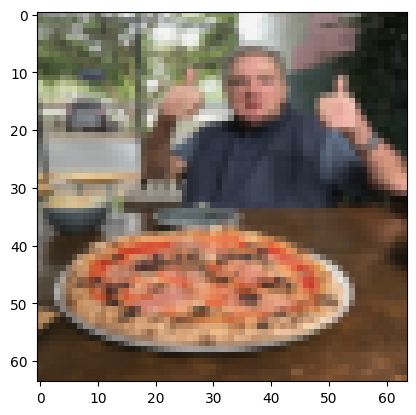

In [84]:
plt.imshow(custom_image_transformed.permute(1, 2, 0));

In [85]:
custom_image_transformed.shape, custom_image_transformed.unsqueeze(dim=0).shape

(torch.Size([3, 64, 64]), torch.Size([1, 3, 64, 64]))

In [86]:
# making a prediction with a train PyTorch model

model_1.eval()
with torch.inference_mode():
  custom_image_pred = model_1(custom_image_transformed.unsqueeze(dim=0).to(device))
custom_image_pred

tensor([[ 0.6955, -0.7382, -0.5647]])

- load the image and turn it into a tensor
- make sure the image was the same datatype as the model (torch.float32)
- make sure the image was the same shape (3,64,64) with a batch size (1,3,64,64)
- make sure the image was on the right device


In [87]:
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
custom_image_pred_probs

tensor([[0.6570, 0.1566, 0.1863]])

In [88]:
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)
custom_image_pred_label

tensor([0])

In [89]:
class_names[custom_image_pred_label]

'pizza'

**11. Putting custom image prediction together: building a function**

In [90]:
def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str] = None,
                        transform=None,
                        device: torch.device = device):

    # Load image and scale to 0-1
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32) / 255

    # Transform if necessary
    if transform:
        target_image = transform(target_image)

    model.to(device)
    model.eval()
    with torch.inference_mode():
        target_image = target_image.unsqueeze(dim=0)                          # add batch dim
        target_image_pred = model(target_image.to(device))

    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    plt.imshow(target_image.squeeze().permute(1, 2, 0))
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else:
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False)

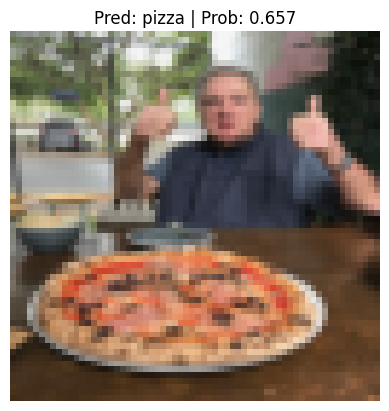

In [91]:
# Pred on our custom image

pred_and_plot_image(model=model_1,
                     image_path=custom_image_path,
                     class_names=class_names,
                     transform=custom_image_transform,
                     device=device)

